# Datathon Deep Learning – Tim T017
Notebook ini disusun mengikuti **alur kerja 6 fase** dari ketentuan.

## Fase 0 – Setup

In [1]:
import os, glob, time, random, json, shutil, joblib, warnings
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

TEAM, SEED = 'T017', 42

# --- Lokasi dataset (Kaggle Dataset yang kamu upload) ---
DATA_ROOT = '/kaggle/input/datasets/sellyrk/dataset-datathon/student'

# Cadangan: kalau path di atas tidak ada, cari otomatis folder dataset_A di /kaggle/input
if not os.path.isdir(DATA_ROOT):
    hits = glob.glob('/kaggle/input/**/dataset_A', recursive=True)
    if not hits:
        raise FileNotFoundError('Folder dataset_A tidak ditemukan di /kaggle/input. '
                                'Cek Add Input -> pastikan dataset sudah ditambahkan ke notebook.')
    DATA_ROOT = os.path.dirname(hits[0])
print('DATA_ROOT:', DATA_ROOT)
print('Isi      :', sorted(os.listdir(DATA_ROOT)))

# --- Folder proyek (output Kaggle) ---
PROJECT = '/kaggle/working/datathon_T017'
for d in ['code', 'models', 'predictions', 'figures']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)

# --- Petakan file tiap dataset ---
def pick(folder, pattern):
    m = sorted(glob.glob(f'{folder}/{pattern}'))
    return m[0] if m else None

PATHS = {}
for key in ['A', 'B', 'C']:
    folder = f'{DATA_ROOT}/dataset_{key}'
    if not os.path.isdir(folder):
        raise FileNotFoundError(f'Folder {folder} tidak ada. Isi DATA_ROOT: {sorted(os.listdir(DATA_ROOT))}')
    PATHS[key] = dict(train=pick(folder, 'train*.csv'),
                      test=pick(folder, 'test*.csv'),
                      sample=pick(folder, 'sample_submission*.csv'))
    print(f'\nDataset {key}: {folder}')
    for k, v in PATHS[key].items():
        print(f'  {k:<7}:', os.path.basename(v) if v else 'TIDAK DITEMUKAN')
    assert PATHS[key]['train'] and PATHS[key]['test'], f'train/test Dataset {key} tidak ditemukan'

# --- Cek ukuran data vs hasil EDA sebelumnya ---
EXPECTED = {'A': (36249, 10), 'B': (63988, 35), 'C': (9600, 5)}
print()
for key, p in PATHS.items():
    shape = pd.read_csv(p['train']).shape
    print(f'Train {key}: {shape}', 'OK' if shape == EXPECTED[key] else f'PERIKSA (diharapkan {EXPECTED[key]})')

DATASETS = {'A': ('train.csv', 'test.csv'), 'B': ('train_B.csv', 'test_B.csv'), 'C': ('train_C.csv', 'test_C.csv')}
print('\nPROJECT:', PROJECT, '->', sorted(os.listdir(PROJECT)))

DATA_ROOT: /kaggle/input/datasets/sellyrk/dataset-datathon/student
Isi      : ['PERATURAN.md', 'dataset_A', 'dataset_B', 'dataset_C']

Dataset A: /kaggle/input/datasets/sellyrk/dataset-datathon/student/dataset_A
  train  : train.csv
  test   : test.csv
  sample : sample_submission.csv

Dataset B: /kaggle/input/datasets/sellyrk/dataset-datathon/student/dataset_B
  train  : train_B.csv
  test   : test_B.csv
  sample : sample_submission_B.csv

Dataset C: /kaggle/input/datasets/sellyrk/dataset-datathon/student/dataset_C
  train  : train_C.csv
  test   : test_C.csv
  sample : sample_submission_C.csv

Train A: (36249, 10) OK
Train B: (63988, 35) OK
Train C: (9600, 5) OK

PROJECT: /kaggle/working/datathon_T017 -> ['code', 'figures', 'models', 'predictions']


## Fase 1 – Exploratory Data Analysis (EDA)


===== DATASET A =====
Train: (36249, 10) | Test: (9063, 9)
Jumlah fitur       : 8 (0 kategorikal)
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    42.45
1    57.55


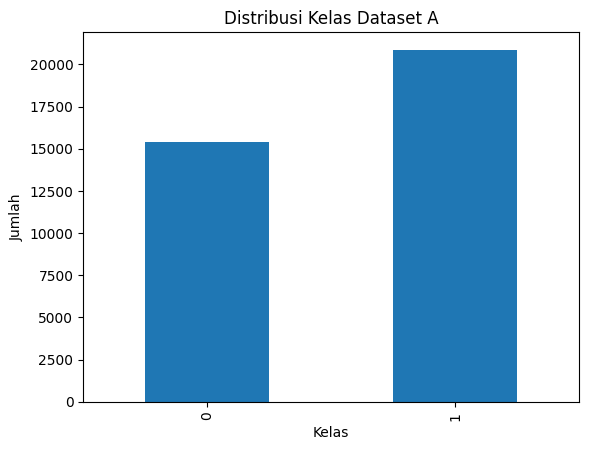


===== DATASET B =====
Train: (63988, 35) | Test: (15998, 34)
Jumlah fitur       : 33 (0 kategorikal)
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    16.67
1    16.67
2    16.67
3    16.67
4    16.67
5    16.67


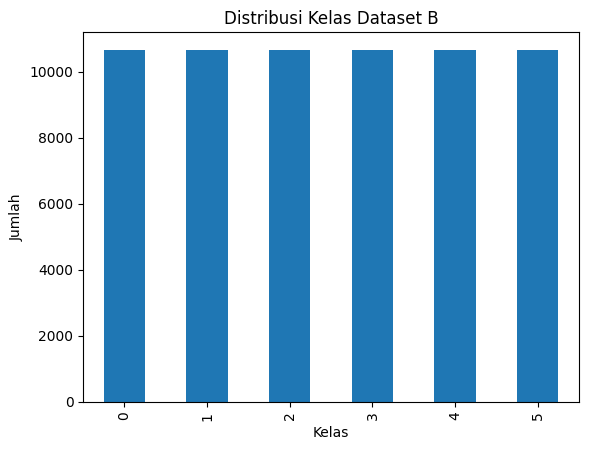


===== DATASET C =====
Train: (9600, 5) | Test: (2400, 4)
Jumlah fitur       : 3 (0 kategorikal)
Missing train/test : 0 / 0
Duplikat baris     : 0
Kolom konstan      : []
Kolom test = train : True
Distribusi kelas (%):
target
0    64.47
1    35.53


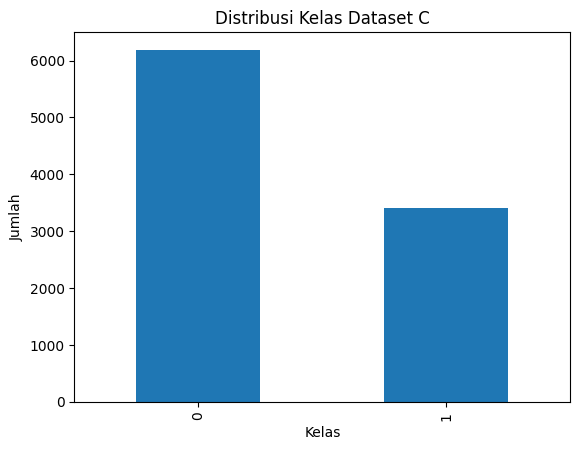

,dataset,n_train,n_test,n_features,n_categorical,missing_train,missing_test,n_classes,majority_class_pct,minority_class_pct,imbalance_ratio
0,A,36249,9063,8,0,0,0,2,57.55,42.45,1.36
1,B,63988,15998,33,0,0,0,6,16.67,16.67,1.00
2,C,9600,2400,3,0,0,0,2,64.47,35.53,1.81


In [2]:
eda_rows, RAW = [], {}
for key, p in PATHS.items():
    train = pd.read_csv(p['train'])
    test  = pd.read_csv(p['test'])
    RAW[key] = (train, test)

    feats = [c for c in train.columns if c not in ('sample_id', 'target')]
    cls = train['target'].value_counts(normalize=True).sort_index()
    n_cat = len(train[feats].select_dtypes(exclude='number').columns)
    const = [c for c in feats if train[c].nunique() <= 1]

    print(f'\n===== DATASET {key} =====')
    print('Train:', train.shape, '| Test:', test.shape)
    print('Jumlah fitur       :', len(feats), f'({n_cat} kategorikal)')
    print('Missing train/test :', int(train.isna().sum().sum()), '/', int(test.isna().sum().sum()))
    print('Duplikat baris     :', int(train[feats].duplicated().sum()))
    print('Kolom konstan      :', const)
    print('Kolom test = train :', set(test.columns) == set(feats) | {'sample_id'})
    print('Distribusi kelas (%):'); print((cls * 100).round(2).to_string())

    eda_rows.append(dict(dataset=key, n_train=len(train), n_test=len(test), n_features=len(feats),
                         n_categorical=n_cat, missing_train=int(train.isna().sum().sum()),
                         missing_test=int(test.isna().sum().sum()), n_classes=train['target'].nunique(),
                         majority_class_pct=round(cls.max() * 100, 2), minority_class_pct=round(cls.min() * 100, 2),
                         imbalance_ratio=round(cls.max() / cls.min(), 2)))

    ax = (train['target'].value_counts().sort_index()).plot(kind='bar', title=f'Distribusi Kelas Dataset {key}')
    ax.set_xlabel('Kelas'); ax.set_ylabel('Jumlah')
    plt.savefig(f'{PROJECT}/figures/eda_class_{key}.png', dpi=150, bbox_inches='tight'); plt.show()

eda_df = pd.DataFrame(eda_rows)
eda_df.to_csv(f'{PROJECT}/eda_summary.csv', index=False)
eda_df

## Fase 2 – Preprocessing & Pembagian Data (80:20)

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import random
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
set_seed()

DATA = {}
for key, (train, test) in RAW.items():
    X = train.drop(columns=['sample_id', 'target'])      # sample_id TIDAK jadi fitur
    X_test = test.drop(columns=['sample_id'])
    le = LabelEncoder().fit(train['target'])               # label -> 0..K-1
    y = le.transform(train['target'])

    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

    num_cols = X.select_dtypes(include='number').columns.tolist()
    cat_cols = X.select_dtypes(exclude='number').columns.tolist()
    parts = [('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols)]
    if cat_cols:
        parts.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                       ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols))
    pre = ColumnTransformer(parts)

    Xtr_s  = pre.fit_transform(X_tr).astype('float32')     # fit HANYA di train
    Xval_s = pre.transform(X_val).astype('float32')
    Xte_s  = pre.transform(X_test).astype('float32')

    joblib.dump(pre, f'{PROJECT}/models/preprocessor_{key.lower()}.pkl')
    joblib.dump(le,  f'{PROJECT}/models/labelencoder_{key.lower()}.pkl')

    DATA[key] = dict(Xtr=Xtr_s, Xval=Xval_s, Xte=Xte_s, ytr=y_tr, yval=y_val, le=le,
                     test_ids=test['sample_id'].values, n_classes=len(le.classes_))
    print(f'Dataset {key}: train {Xtr_s.shape} | val {Xval_s.shape} | test {Xte_s.shape} | kelas {list(le.classes_)}')

Dataset A: train (28999, 8) | val (7250, 8) | test (9063, 8) | kelas [np.int64(0), np.int64(1)]
Dataset B: train (51190, 33) | val (12798, 33) | test (15998, 33) | kelas [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Dataset C: train (7680, 3) | val (1920, 3) | test (2400, 3) | kelas [np.int64(0), np.int64(1)]


## Fase 3 – Eksperimen Model Neural Network

In [ ]:
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# --- Config 1 & 2: sama untuk semua dataset ---
CFG1 = dict(name='Config_1_Baseline', layers=[64, 32],       act='relu', dropout=0.3, lr=1e-3, batch=32,
            opt='adam', bn=False, epochs=100, patience=12, lr_patience=4)
CFG2 = dict(name='Config_2_Deeper',   layers=[128, 64, 32],  act='relu', dropout=0.2, lr=5e-4, batch=64,
            opt='adam', bn=False, epochs=100, patience=12, lr_patience=4)
CONFIGS = [CFG1, CFG2]

# --- Config 3: hasil hyperparameter tuning (Fase 3c), berbeda per dataset ---
TUNED = {
    'A': dict(name='Config_3_Tuned', layers=[128, 128, 128], act='relu', dropout=0.0, lr=1e-3, batch=64,
              opt='adam', bn=False, epochs=300, patience=20, lr_patience=6),   # Tune2_A_01
    'B': dict(name='Config_3_Tuned', layers=[256, 128, 64],  act='gelu', dropout=0.2, lr=1e-3, batch=64,
              opt='adam', bn=False, epochs=300, patience=20, lr_patience=6),   # Tune2_B_04
    'C': dict(name='Config_3_Tuned', layers=[128, 128, 128], act='relu', dropout=0.3, lr=3e-4, batch=64,
              opt='adam', bn=False, epochs=300, patience=20, lr_patience=6),   # Tune2_C_02
}

def build_model(n_feat, n_cls, c):
    m = models.Sequential([layers.Input(shape=(n_feat,))])
    for u in c['layers']:
        m.add(layers.Dense(u))
        if c['bn']: m.add(layers.BatchNormalization())
        m.add(layers.Activation(c['act']))
        m.add(layers.Dropout(c['dropout']))
    if n_cls > 2:
        m.add(layers.Dense(n_cls, activation='softmax')); loss = 'sparse_categorical_crossentropy'
    else:
        m.add(layers.Dense(1, activation='sigmoid'));      loss = 'binary_crossentropy'
    opt = (tf.keras.optimizers.AdamW(learning_rate=c['lr'], weight_decay=1e-4) if c['opt'] == 'adamw'
           else tf.keras.optimizers.Adam(learning_rate=c['lr']))
    m.compile(optimizer=opt, loss=loss, metrics=['accuracy'])
    return m

def to_labels(prob, n_cls):
    return np.argmax(prob, axis=1) if n_cls > 2 else (prob.ravel() > 0.5).astype(int)

rows, RESULTS = [], {}
for key, d in DATA.items():
    n_cls = d['n_classes']
    cfgs = CONFIGS + [TUNED[key]]
    RESULTS[key] = dict(runs=[])
    print(f'\n=========== DATASET {key} (kelas={n_cls}) ===========')

    for c in cfgs:
        set_seed()
        model = build_model(d['Xtr'].shape[1], n_cls, c)
        cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=c['patience'], restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=c['lr_patience'], min_lr=1e-5)]
        t0 = time.time()
        h = model.fit(d['Xtr'], d['ytr'], validation_data=(d['Xval'], d['yval']),
                      epochs=c['epochs'], batch_size=c['batch'], callbacks=cbs, verbose=0)
        t_train = time.time() - t0

        vpred = to_labels(model.predict(d['Xval'], verbose=0), n_cls)
        acc = accuracy_score(d['yval'], vpred)
        print(f"{c['name']:<18} val_acc={acc:.4f} | val_err={1-acc:.4f} | epoch={len(h.history['loss'])} | {t_train:.1f}s")

        rows.append(dict(dataset=key, config_name=c['name'], seed=SEED,
                         val_accuracy=round(acc, 5), val_error=round(1 - acc, 5), training_time=round(t_train, 2),
                         hidden_layers=str(c['layers']), activation=c['act'], dropout=c['dropout'],
                         learning_rate=c['lr'], batch_size=c['batch'], optimizer=c['opt'],
                         batch_norm=c['bn'], max_epochs=c['epochs'], epochs_run=len(h.history['loss'])))
        RESULTS[key]['runs'].append(dict(cfg=c, model=model, hist=h.history, vpred=vpred, acc=acc))

    # model terbaik
    best = max(RESULTS[key]['runs'], key=lambda r: r['acc'])
    RESULTS[key]['best'] = best
    best['model'].save(f"{PROJECT}/models/model_{key.lower()}_best.keras")
    print(f"--> TERBAIK Dataset {key}: {best['cfg']['name']} ({best['acc']:.4f})")

    # kurva loss semua konfigurasi
    fig, axs = plt.subplots(1, len(cfgs), figsize=(5 * len(cfgs), 3.6), sharey=True)
    for ax, r in zip(axs, RESULTS[key]['runs']):
        ax.plot(r['hist']['loss'], label='Train'); ax.plot(r['hist']['val_loss'], label='Validation')
        ax.set_title(f"{r['cfg']['name']}\nval_acc={r['acc']:.4f}", fontsize=10); ax.set_xlabel('Epoch'); ax.legend()
    axs[0].set_ylabel('Loss'); fig.suptitle(f'Training vs Validation Loss – Dataset {key}')
    plt.savefig(f'{PROJECT}/figures/loss_{key}.png', dpi=150, bbox_inches='tight'); plt.show()

    # confusion matrix model terbaik
    ConfusionMatrixDisplay(confusion_matrix(d['yval'], best['vpred'])).plot(cmap='Blues')
    plt.title(f"Confusion Matrix Validasi – Dataset {key} ({best['cfg']['name']})")
    plt.savefig(f'{PROJECT}/figures/cm_{key}.png', dpi=150, bbox_inches='tight'); plt.show()

exp_df = pd.DataFrame(rows)
exp_df.to_csv(f'{PROJECT}/experiments.csv', index=False)
exp_df[['dataset', 'config_name', 'seed', 'val_accuracy', 'val_error', 'training_time']]


=========== DATASET A (kelas=2) ===========


2026-10-18 07:40:05.655821: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Fase 3.5 – Pembanding Non-Deep-Learning (untuk laporan)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

cmp_rows = []
for key, d in DATA.items():
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(d['Xtr'], d['ytr'])
    cmp_rows.append(dict(dataset=key, model='RandomForest (pembanding)', val_accuracy=accuracy_score(d['yval'], rf.predict(d['Xval'])),
                         time_s=round(time.time() - t0, 1)))
    if HAS_XGB:
        t0 = time.time()
        xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1).fit(d['Xtr'], d['ytr'])
        cmp_rows.append(dict(dataset=key, model='XGBoost (pembanding)', val_accuracy=accuracy_score(d['yval'], xgb.predict(d['Xval'])),
                             time_s=round(time.time() - t0, 1)))
    b = RESULTS[key]['best']
    cmp_rows.append(dict(dataset=key, model=f"MLP terbaik – {b['cfg']['name']}", val_accuracy=b['acc'], time_s=np.nan))

cmp_df = pd.DataFrame(cmp_rows).sort_values(['dataset', 'val_accuracy'], ascending=[True, False])
cmp_df['val_accuracy'] = cmp_df['val_accuracy'].round(4)
cmp_df.to_csv(f'{PROJECT}/baseline_comparison.csv', index=False)
cmp_df

## Fase 4 – Generate & Validasi File Submission

In [ ]:
# ===== Fase 4 – Generate & Validasi File Submission =====
# Pilih attempt & konfigurasi per dataset. None = pakai model terbaik otomatis (kemungkinan Config_3_Tuned).
ATTEMPT_PLAN = {'A': '01', 'B': '01', 'C': '01'}   # ganti ke '02'/'03' jika nomor itu sudah dikirim
CONFIG_PICK  = {'A': None, 'B': None, 'C': None}   # atau nama config, mis. 'Config_3_Tuned'
OVERWRITE = False

assert 'RESULTS' in globals() and all('best' in RESULTS[k] for k in DATA), \
    'RESULTS belum lengkap. Jalankan Fase 2 dan Fase 3 terlebih dahulu.'

def find_sample_submission(key):
    return PATHS[key]['sample']

report = []
for key, d in DATA.items():
    runs = {r['cfg']['name']: r for r in RESULTS[key]['runs']}
    run = runs[CONFIG_PICK[key]] if CONFIG_PICK[key] else RESULTS[key]['best']

    pred_idx = to_labels(run['model'].predict(d['Xte'], verbose=0), d['n_classes'])
    pred = d['le'].inverse_transform(pred_idx)                    # kembalikan ke label asli
    sub = pd.DataFrame({'sample_id': d['test_ids'], 'target': pred})

    fname = f"{PROJECT}/predictions/{TEAM}_{key}_{ATTEMPT_PLAN[key]}.csv"
    if os.path.exists(fname) and not OVERWRITE:
        print(f'[SKIP] {os.path.basename(fname)} sudah ada (set OVERWRITE=True untuk menimpa)'); continue
    sub.to_csv(fname, index=False)

    # --- validasi aturan ---
    size_mb = os.path.getsize(fname) / 1e6
    chk = pd.read_csv(fname)
    checks = {
        '2 kolom (sample_id,target)': list(chk.columns) == ['sample_id', 'target'],
        'ID unik (1x)': chk['sample_id'].is_unique,
        'jumlah baris = test.csv': len(chk) == len(RAW[key][1]),
        'tanpa NaN': not chk.isna().any().any(),
        'ukuran < 5 MB': size_mb < 5,
        'nama file sesuai format': os.path.basename(fname) == f'{TEAM}_{key}_{ATTEMPT_PLAN[key]}.csv',
    }
    ss = find_sample_submission(key)
    if ss:
        ssdf = pd.read_csv(ss)
        checks['ID sama dgn sample_submission'] = set(ssdf['sample_id']) == set(chk['sample_id'])

    # --- cek kewajaran distribusi prediksi vs distribusi train (informasi, bukan aturan) ---
    train_dist = RAW[key][0]['target'].value_counts(normalize=True).sort_index()
    pred_dist  = chk['target'].value_counts(normalize=True).reindex(train_dist.index).fillna(0)
    max_gap = float((pred_dist - train_dist).abs().max())

    config_name = run['cfg']['name']
    print(f"\n{os.path.basename(fname)} | {config_name} | val_acc={run['acc']:.4f} | {size_mb:.2f} MB")
    print('  distribusi prediksi (%):', (pred_dist * 100).round(1).to_dict())
    print('  distribusi train    (%):', (train_dist * 100).round(1).to_dict())
    print(f"  [{'OK' if max_gap < 0.10 else 'PERIKSA'}] selisih distribusi terbesar {max_gap*100:.1f} poin")
    for k, v in checks.items(): print(f"  [{'OK' if v else 'GAGAL'}] {k}")
    report.append(dict(file=os.path.basename(fname), config=config_name, val_acc=round(run['acc'], 5),
                       all_ok=all(checks.values())))

pd.DataFrame(report)

## Fase 5 – Ringkasan Hasil

In [ ]:
from importlib.metadata import version, PackageNotFoundError
pkgs = ['tensorflow', 'scikit-learn', 'pandas', 'numpy', 'joblib', 'matplotlib', 'xgboost']
lines = []
for p in pkgs:
    try: lines.append(f'{p}=={version(p)}')
    except PackageNotFoundError: pass
open(f'{PROJECT}/requirements.txt', 'w').write('\n'.join(lines) + '\n')
print(open(f'{PROJECT}/requirements.txt').read())

print('Ringkasan model terbaik per dataset:')
summary = pd.DataFrame([dict(dataset=k, best_config=v['best']['cfg']['name'], val_accuracy=round(v['best']['acc'], 4),
                             val_error=round(1 - v['best']['acc'], 4)) for k, v in RESULTS.items()])
display(summary)
print('\nIsi proyek:')
for root, _, files in os.walk(PROJECT):
    for f in sorted(files): print(' ', os.path.relpath(os.path.join(root, f), PROJECT))

## Fase 6 – Simpan ZIP

In [ ]:
# Buat ZIP proyek (jalankan setelah notebook .ipynb dimasukkan ke folder code/)
zip_base = f'/kaggle/working/{TEAM}_final'
to_zip   = '/kaggle/working/zip_tmp'
shutil.rmtree(to_zip, ignore_errors=True); os.makedirs(to_zip)
for item in ['code', 'models', 'predictions', 'requirements.txt', 'experiments.csv']:
    src = f'{PROJECT}/{item}'
    if os.path.isdir(src): shutil.copytree(src, f'{to_zip}/{item}')
    elif os.path.exists(src): shutil.copy(src, to_zip)
path = shutil.make_archive(zip_base, 'zip', to_zip)
shutil.copy(path, PROJECT)
print('ZIP dibuat:', path, f'({os.path.getsize(path)/1e6:.1f} MB) – salinan juga di', PROJECT)